# 03 — Motif & Discord Discovery

**Input:** `CMI_timeseries_prepared.pkl` (prodotto da `02_data_preparation.ipynb`).

**Cosa è stato fatto in questo notebook:**
- Ricerca di **motif** (pattern ricorrenti) e **discord** (sottosequenze anomale) su `enmo` pulito, con sottosequenze di `m = 48` step (~1/4 di ciclo); le finestre consecutive di un soggetto sono concatenate con un `NaN` di separazione.
- **Dentro un soggetto** (un id per classe, quello con più finestre): confronto fra **Random Projection** (SAX + collision matrix, approssimato) e **Matrix Profile** (`stumpy`, esatto).
- **Fra le classi:** AB-join su un pool bilanciato di finestre di train e **contrasto** `P_AB − P_AA` per trovare forme tipiche di una classe; discord globali.

**Risultati principali:** i motif sono per lo più picchi isolati (effetto anche della z-normalizzazione); Random Projection non ritrova il motif esatto migliore; le forme candidate a massimo contrasto non generalizzano sul test (AUC per id 0.35–0.68) → collegamento con gli shapelet della classificazione.

## MOTIF & DISCORD DISCOVERY

Cerchiamo pattern ricorrenti (motif) e sottosequenze anomale (discord) in `enmo`, a due livelli:

1. **Dentro un soggetto**: per un id di classe 0 e uno di classe 1 (quelli con più finestre) usiamo **Random Projection** (Chiu, Keogh & Lonardi, 2003), approssimato e basato su SAX, e **Matrix Profile** (Yeh et al., 2016, via `stumpy`), esatto.
2. **Fra le classi**: confrontiamo con un AB-join quanto ogni sottosequenza di una classe trova un gemello nell'altra. È il collegamento diretto con gli shapelet.

**Scelte rispetto alla prima versione di questa sezione:**
- si usano i dati **puliti** di P1-P3, non il dataset grezzo;
- fra una finestra e la successiva inseriamo un `NaN`: le finestre sono giornate quasi contigue ma non sappiamo se la giunzione sia esatta, quindi `stumpy` ignora le sottosequenze a cavallo, che nella prima versione erano il 23% del totale e includevano il motif principale;
- `m=48` step è circa **un quarto di ciclo** (~6 ore), non un giorno intero (vedi P4).

In [55]:
import pickle, time, os, warnings
# avvisi numerici innocui di scikit-learn su macOS nei prodotti matrice (la finitezza degli score è controllata in fondo)
warnings.filterwarnings('ignore', category=RuntimeWarning, module='sklearn')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import defaultdict
from scipy.stats import norm
import stumpy
from sklearn.metrics import roc_auc_score

with open('CMI_timeseries_prepared.pkl', 'rb') as f:
    PREP = pickle.load(f)
tr, te = PREP['train_idx'], PREP['test_idx']
y, ids, meta = PREP['y'], PREP['ids'], PREP['meta']
enmo_clean = PREP['X_raw'][:, 0, :].astype(np.float64)
SEED = PREP['params']['RANDOM_STATE']
C0, C1 = '#2a78d6', '#eb6834'
m = 48

def concat_windows(win_idx):
    """Concatena le finestre inserendo un NaN fra l'una e l'altra; owner[t] = finestra a cui appartiene t (-1 sul NaN)."""
    parts, owner = [], []
    for k, w in enumerate(win_idx):
        parts.append(enmo_clean[w]); owner.append(np.full(200, w))
        if k < len(win_idx) - 1:
            parts.append([np.nan]); owner.append([-1])
    return np.concatenate(parts), np.concatenate(owner)

win_per_id = meta.groupby('id').agg(n=('y', 'size'), y=('y', 'first'))
subjects = {c: int(win_per_id[win_per_id.y == c].n.idxmax()) for c in [0, 1]}
series = {}
for c, sid in subjects.items():
    w = meta[meta.id == sid].sort_values('relative_date_PCIAT').index.values
    series[c] = concat_windows(w)
    rd = meta.loc[w, 'relative_date_PCIAT']
    print(f"classe {c}: id={sid}, {len(w)} finestre, relative_date da {rd.min():.0f} a {rd.max():.0f}, serie di {len(series[c][0])} punti")

classe 0: id=2043, 36 finestre, relative_date da 2 a 37, serie di 7235 punti
classe 1: id=339, 32 finestre, relative_date da 8 a 39, serie di 6431 punti


### Random Projection (SAX + collision matrix)

Ogni sottosequenza valida viene z-normalizzata, ridotta con PAA a `w=8` segmenti e mappata su un alfabeto di `a=5` simboli. Per `R=300` volte si mascherano 2 colonne a caso e si contano le **collisioni** fra le sottosequenze che coincidono sulle altre. Le coppie con più collisioni sono candidati da verificare con la distanza euclidea vera, perché SAX perde informazione.

In [56]:
def random_projection(T, m=48, w=8, a=5, R=300, mask_out=2, K=3, max_bucket=400, seed=42):
    starts = np.array([i for i in range(len(T) - m + 1) if not np.isnan(T[i:i + m]).any()])
    subs = np.stack([T[i:i + m] for i in starts])
    sd = subs.std(axis=1, keepdims=True); sd[sd == 0] = 1e-8
    subs_norm = (subs - subs.mean(axis=1, keepdims=True)) / sd
    seg = m // w
    rp_paa = subs_norm[:, :seg * w].reshape(len(starts), w, seg).mean(axis=2)
    rp_sax = np.searchsorted(norm.ppf(np.linspace(0, 1, a + 1)[1:-1]), rp_paa)
    rng = np.random.default_rng(seed)
    counts = defaultdict(int)
    skipped = 0
    for _ in range(R):
        cols = rng.choice(w, size=w - mask_out, replace=False)
        buckets = defaultdict(list)
        for i, row in enumerate(rp_sax[:, cols]):
            buckets[tuple(row)].append(i)
        for mem in buckets.values():
            if len(mem) < 2:
                continue
            if len(mem) > max_bucket:       # bucket degeneri: troppo costosi, li contiamo per dichiararlo
                skipped += 1
                continue
            mem = np.array(mem)
            ii, jj = np.triu_indices(len(mem), k=1)
            keep = np.abs(starts[mem[ii]] - starts[mem[jj]]) >= m   # esclude le coppie banali
            for x, z in zip(mem[ii][keep], mem[jj][keep]):
                counts[(x, z)] += 1
    cand = [p for p, c in counts.items() if c >= R // 2]
    dist = np.array([np.linalg.norm(subs_norm[a_] - subs_norm[b_]) for a_, b_ in cand])
    chosen = []
    for k in np.argsort(dist):
        i_, j_ = starts[cand[k][0]], starts[cand[k][1]]
        if any(abs(i_ - q) < m or abs(j_ - q) < m for c_ in chosen for q in c_[:2]):
            continue
        chosen.append((int(i_), int(j_), float(dist[k]), counts[cand[k]]))
        if len(chosen) == K:
            break
    return chosen, len(counts), len(cand), skipped

rp_res = {}
for c, (T, _) in series.items():
    t0 = time.perf_counter()
    rp_res[c], n_pairs, n_cand, skipped = random_projection(T, m=m)
    print(f"classe {c}: {n_pairs} coppie con collisioni, {n_cand} con >=150/300, {skipped} bucket saltati ({time.perf_counter() - t0:.0f} s)")
    for r in rp_res[c]:
        print(f"   coppia ({r[0]}, {r[1]})  distanza={r[2]:.3f}  collisioni={r[3]}/300")

classe 0: 179434 coppie con collisioni, 2422 con >=150/300, 0 bucket saltati (8 s)
   coppia (5047, 6646)  distanza=3.255  collisioni=300/300
   coppia (3035, 6031)  distanza=3.281  collisioni=300/300
   coppia (2936, 4860)  distanza=3.441  collisioni=300/300


classe 1: 161341 coppie con collisioni, 2628 con >=150/300, 0 bucket saltati (8 s)
   coppia (2245, 5665)  distanza=3.023  collisioni=300/300
   coppia (4048, 5861)  distanza=3.378  collisioni=300/300
   coppia (24, 3884)  distanza=3.825  collisioni=300/300


### Matrix Profile

Per ogni sottosequenza il Matrix Profile registra la distanza z-normalizzata dal vicino più simile, escludendo l'intorno banale. Valori bassi indicano un motif, valori alti un discord. Il calcolo è esatto, quindi è il riferimento con cui giudicare Random Projection.

In [57]:
def top_motifs(D, I, m, k=3):
    D = D.copy(); out = []
    for _ in range(k):
        if not np.isfinite(D).any():
            break
        i = int(np.nanargmin(np.where(np.isfinite(D), D, np.nan)))
        j = int(I[i]); out.append((i, j, float(D[i])))
        for q in (i, j):
            D[max(0, q - m):q + m] = np.inf
    return out

def top_discords(D, m, k=3):
    W = np.where(np.isfinite(D), D, -np.inf); out = []
    for _ in range(k):
        i = int(np.argmax(W)); out.append((i, float(D[i])))
        W[max(0, i - m // 2):i + m // 2] = -np.inf
    return out

mp_res = {}
for c, (T, owner) in series.items():
    prof = stumpy.stump(T, m=m)
    D, I = prof[:, 0].astype(float), prof[:, 1].astype(int)
    mot, dis = top_motifs(D, I, m), top_discords(D, m)
    mp_res[c] = dict(D=D, I=I, motifs=mot, discords=dis)
    print(f"classe {c}, id {subjects[c]}: profilo medio {D[np.isfinite(D)].mean():.2f}")
    for i, j, d in mot:
        n_occ = len(stumpy.match(T[i:i + m], T, max_distance=2 * d)) if d > 0 else 0
        print(f"   motif ({i}, {j})  d={d:.3f}  occorrenze entro 2d: {n_occ}  step locali: {i % 201}, {j % 201}")
    for i, d in dis:
        print(f"   discord t={i}  d={d:.3f}  step locale {i % 201}, media enmo {np.nanmean(T[i:i + m]):.3f}")

classe 0, id 2043: profilo medio 5.10


   motif (5347, 7179)  d=1.972  occorrenze entro 2d: 4  step locali: 121, 144
   motif (3885, 4434)  d=2.176  occorrenze entro 2d: 13  step locali: 66, 12
   motif (5550, 7179)  d=2.241  occorrenze entro 2d: 6  step locali: 123, 144
   discord t=1861  d=7.031  step locale 52, media enmo 0.055
   discord t=4526  d=7.024  step locale 104, media enmo 0.135
   discord t=1078  d=6.992  step locale 73, media enmo 0.048
classe 1, id 339: profilo medio 5.40
   motif (2522, 5669)  d=2.936  occorrenze entro 2d: 44  step locali: 110, 41
   motif (2245, 5665)  d=3.023  occorrenze entro 2d: 17  step locali: 34, 37
   motif (2845, 5646)  d=3.036  occorrenze entro 2d: 57  step locali: 31, 18
   discord t=3030  d=7.405  step locale 15, media enmo 0.012
   discord t=4237  d=7.313  step locale 16, media enmo 0.013
   discord t=5361  d=7.226  step locale 135, media enmo 0.052


In [58]:
print("Random Projection vs Matrix Profile (d esatta del miglior motif e rapporto):")
for c in series:
    best = mp_res[c]['motifs'][0][2]; D, I = mp_res[c]['D'], mp_res[c]['I']
    for i, j, d, cnt in rp_res[c]:
        print(f"  classe {c}: RP ({i},{j}) d={d:.2f} | MP migliore d={best:.2f} | rapporto {d / best:.2f} | "
              f"percentile di P[i] nel profilo: {(D[np.isfinite(D)] < D[i]).mean():.1%} | vicino esatto di i a distanza {D[i]:.2f}")

Random Projection vs Matrix Profile (d esatta del miglior motif e rapporto):
  classe 0: RP (5047,6646) d=3.25 | MP migliore d=1.97 | rapporto 1.65 | percentile di P[i] nel profilo: 1.2% | vicino esatto di i a distanza 3.25
  classe 0: RP (3035,6031) d=3.28 | MP migliore d=1.97 | rapporto 1.66 | percentile di P[i] nel profilo: 1.3% | vicino esatto di i a distanza 3.28
  classe 0: RP (2936,4860) d=3.44 | MP migliore d=1.97 | rapporto 1.75 | percentile di P[i] nel profilo: 2.0% | vicino esatto di i a distanza 3.44
  classe 1: RP (2245,5665) d=3.02 | MP migliore d=2.94 | rapporto 1.03 | percentile di P[i] nel profilo: 0.0% | vicino esatto di i a distanza 3.02
  classe 1: RP (4048,5861) d=3.38 | MP migliore d=2.94 | rapporto 1.15 | percentile di P[i] nel profilo: 1.2% | vicino esatto di i a distanza 3.38
  classe 1: RP (24,3884) d=3.82 | MP migliore d=2.94 | rapporto 1.30 | percentile di P[i] nel profilo: 4.7% | vicino esatto di i a distanza 3.82


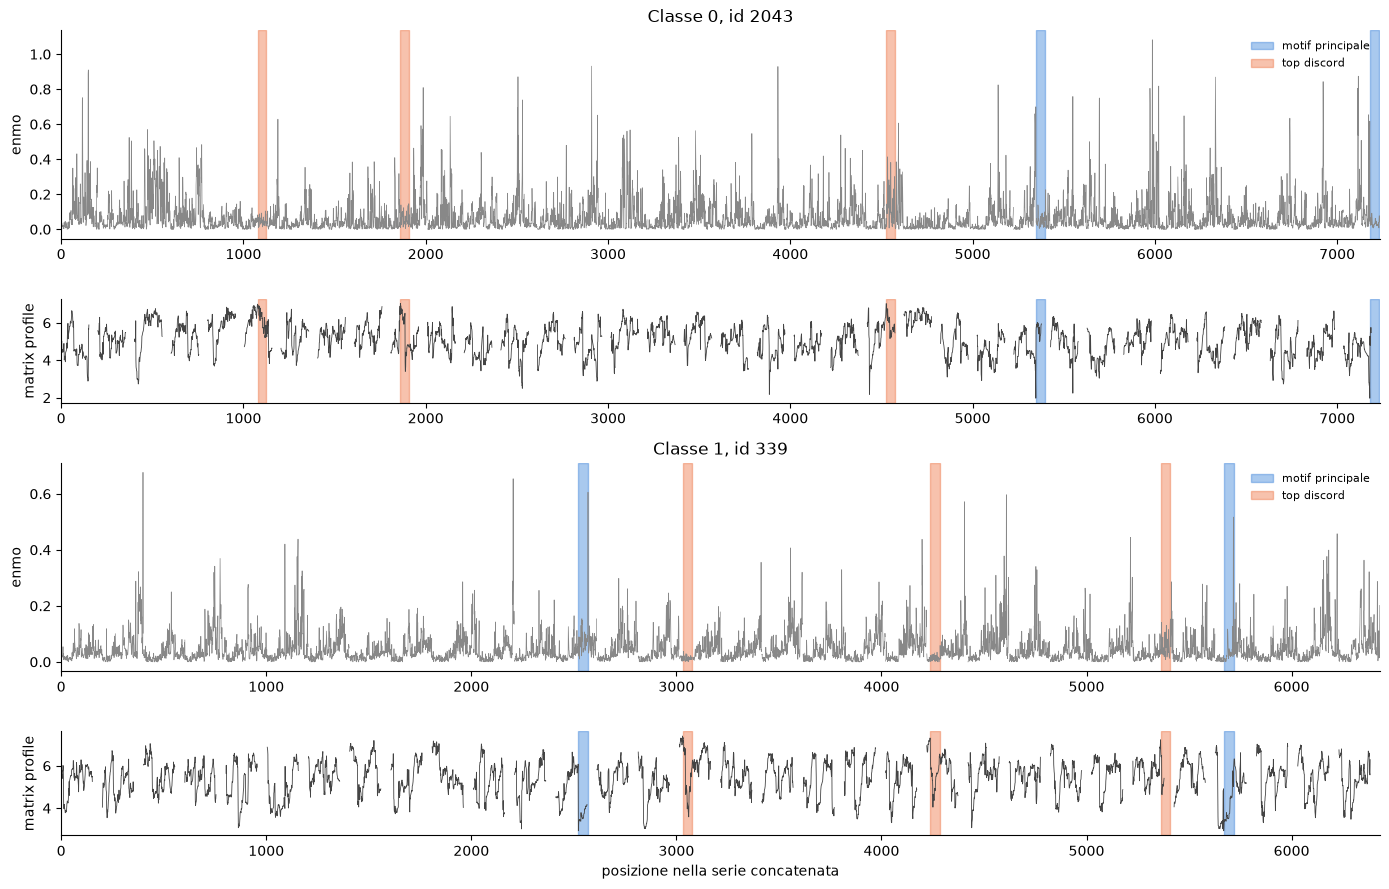

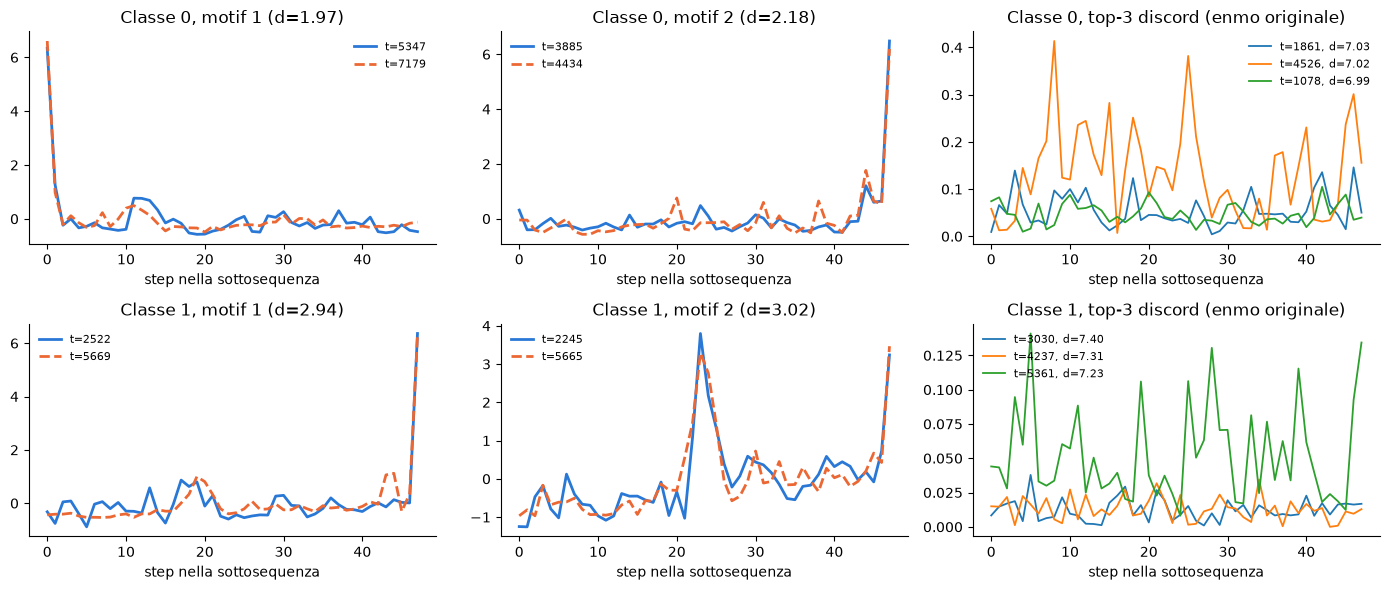

In [59]:
fig, axes = plt.subplots(4, 1, figsize=(14, 9), gridspec_kw={'height_ratios': [2, 1, 2, 1]})
for row, c in enumerate(series):
    T = series[c][0]; r = mp_res[c]
    ax, ax2 = axes[2 * row], axes[2 * row + 1]
    ax.plot(T, color='#888888', linewidth=0.5)
    for k, (i, j, _) in enumerate(r['motifs'][:1]):
        for q in (i, j):
            ax.axvspan(q, q + m, color=C0, alpha=0.4, label='motif principale' if q == i else None)
            ax2.axvspan(q, q + m, color=C0, alpha=0.4)
    for k, (i, _) in enumerate(r['discords']):
        ax.axvspan(i, i + m, color=C1, alpha=0.4, label='top discord' if k == 0 else None)
        ax2.axvspan(i, i + m, color=C1, alpha=0.4)
    ax.set_ylabel('enmo'); ax.set_title(f'Classe {c}, id {subjects[c]}'); ax.legend(frameon=False, loc='upper right', fontsize=8)
    ax2.plot(np.where(np.isfinite(r['D']), r['D'], np.nan), color='#444444', linewidth=0.6); ax2.set_ylabel('matrix profile')
    for a_ in (ax, ax2):
        a_.spines[['top', 'right']].set_visible(False); a_.set_xlim(0, len(T))
axes[-1].set_xlabel('posizione nella serie concatenata')
plt.tight_layout(); plt.show()

def zn(x):
    s = x.std(); return (x - x.mean()) / (s if s > 0 else 1e-8)

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for row, c in enumerate(series):
    T = series[c][0]; r = mp_res[c]
    for col, (i, j, d) in enumerate(r['motifs'][:2]):
        axes[row, col].plot(zn(T[i:i + m]), color=C0, linewidth=2, label=f't={i}')
        axes[row, col].plot(zn(T[j:j + m]), color=C1, linewidth=2, linestyle='--', label=f't={j}')
        axes[row, col].set_title(f'Classe {c}, motif {col + 1} (d={d:.2f})'); axes[row, col].legend(frameon=False, fontsize=8)
    for k, (i, d) in enumerate(r['discords']):
        axes[row, 2].plot(T[i:i + m], linewidth=1.3, label=f't={i}, d={d:.2f}')
    axes[row, 2].set_title(f'Classe {c}, top-3 discord (enmo originale)'); axes[row, 2].legend(frameon=False, fontsize=8)
    for a_ in axes[row]:
        a_.spines[['top', 'right']].set_visible(False); a_.set_xlabel('step nella sottosequenza')
plt.tight_layout(); plt.show()

**Risultato:**

- **Motif.** I motif principali (d=1.97 per l'id 2043, d=2.94 per l'id 339) sono per lo più **un singolo picco isolato** su un fondo piatto. Il picco può cadere all'inizio, al centro o alla fine della sottosequenza. Il pattern è banale ed è anche un effetto della z-normalizzazione: un picco fa valere il resto quasi zero, quindi due tratti con un picco allineato risultano simili qualunque sia l'attività di fondo. Il soggetto di classe 1 ha motif più numerosi (44 occorrenze entro 2d, contro 4 per il primo motif dell'id 2043) ma anche più lontani fra loro: il profilo medio è 5.40 contro 5.10. Con un solo soggetto per classe queste differenze **non si possono attribuire alla classe**.
- **Discord.** Non hanno tutti lo stesso significato. Nell'id 2043 il discord t=4526 è davvero un tratto molto attivo e irregolare (enmo medio 0.135, con picchi oltre 0.4). Nell'id 339 i primi due discord (t=3030 e t=4237) hanno enmo medio di appena 0.012-0.013 e cadono all'inizio della finestra, cioè nella parte quieta del ciclo: sono "anomali" perché la z-normalizzazione amplifica un rumore di fondo che non si ripete. Un discord z-normalizzato indica quindi una forma non ripetuta, non necessariamente un comportamento insolito.
- **Random Projection contro Matrix Profile.** RP **non** ritrova il motif migliore. Sull'id 2043 la sua coppia migliore ha d=3.25 contro 1.97 esatta (rapporto 1.65), sull'id 339 d=3.02 contro 2.94 (rapporto 1.03). Le coppie restano buone (percentile ≤4.7% del profilo) e per ciascuna `j` è il vicino esatto di `i`, ma non sono le migliori in assoluto: la soglia di collisioni premia le parole SAX comuni, non la distanza minima. La versione precedente del notebook concludeva il contrario perché accettava una coincidenza con qualunque occorrenza di tre motif con una tolleranza di ±24 step.

### Discord sull'intero dataset e contrasto fra le classi

I motif di un singolo soggetto non dicono nulla sulla differenza fra le classi. Per collegarli agli shapelet calcoliamo, sul **train**, due profili per la classe A rispetto alla classe B:

- `P_AA`: distanza dal vicino più simile dentro la classe A (la sottosequenza si ripete nella sua classe?);
- `P_AB`: distanza dal vicino più simile nell'altra classe (esiste anche lì?).

Il **contrasto** `P_AB - P_AA` è alto per le sottosequenze comuni in A ma assenti in B: un motif della propria classe e un discord rispetto all'altra, cioè un candidato shapelet. Usiamo **una finestra a caso per id**, altrimenti il vicino più simile sarebbe spesso un'altra giornata dello stesso soggetto. Le due classi hanno lo stesso numero di finestre, altrimenti il contrasto favorirebbe la classe più numerosa. Il loro potere discriminante viene poi misurato sul test, aggregando per id.

In [60]:
rng_c = np.random.default_rng(SEED)
tr_meta = meta.iloc[tr]
pool = {c: np.array([rng_c.choice(g.index.values) for _, g in tr_meta[tr_meta.y == c].groupby('id')]) for c in [0, 1]}
n_pool = min(len(pool[0]), len(pool[1]))   # stesso numero di finestre: un pool più grande abbasserebbe da solo le distanze
pool = {c: rng_c.choice(pool[c], size=n_pool, replace=False) for c in [0, 1]}
pool_T = {c: concat_windows(pool[c]) for c in [0, 1]}
print({c: (len(pool[c]), len(pool_T[c][0])) for c in pool})

t0 = time.perf_counter()
P_self = {c: stumpy.stump(pool_T[c][0], m=m)[:, 0].astype(float) for c in [0, 1]}
P_cross = {c: stumpy.stump(pool_T[c][0], m=m, T_B=pool_T[1 - c][0], ignore_trivial=False)[:, 0].astype(float) for c in [0, 1]}
print(f"profili calcolati in {time.perf_counter() - t0:.0f} s")

contrast, candidates = {}, {}
for c in [0, 1]:
    ok = np.isfinite(P_self[c]) & np.isfinite(P_cross[c])
    with np.errstate(invalid='ignore'):      # inf - inf sulle sottosequenze a cavallo, escluse da ok
        contrast[c] = np.where(ok, P_cross[c] - P_self[c], -np.inf)
    work, cand = contrast[c].copy(), []
    for _ in range(5):
        i = int(np.argmax(work)); cand.append(i)
        work[max(0, i - m):i + m] = -np.inf
    candidates[c] = cand
    print(f"classe {c}: contrasto medio {contrast[c][ok].mean():.3f}, std {contrast[c][ok].std():.3f}, massimo {contrast[c][ok].max():.3f}")

# discord globali: sottosequenze lontane da tutte quelle del pool (entrambe le classi)
pool_disc = {}
for c in [0, 1]:
    D_all = np.minimum(P_self[c], P_cross[c])
    pool_disc[c] = top_discords(D_all, m, k=3)
    print(f"classe {c}, discord globali:", [(i, round(d, 2), int(pool_T[c][1][i]), f"step {int(i % 201)}") for i, d in pool_disc[c]])

{0: (98, 19697), 1: (98, 19697)}


profili calcolati in 1 s
classe 0: contrasto medio -0.045, std 0.407, massimo 1.504
classe 1: contrasto medio 0.027, std 0.410, massimo 1.777
classe 0, discord globali: [(15314, 6.96, 608, 'step 38'), (12669, 6.88, 1777, 'step 6'), (17291, 6.88, 1914, 'step 5')]
classe 1, discord globali: [(2229, 7.0, 2771, 'step 18'), (5048, 6.85, 1025, 'step 23'), (7349, 6.84, 3725, 'step 113')]


 classe sorgente     t  step locale  contrasto  P_AA  P_AB  AUC id (train)  AUC id (test)
               0 10658            5       1.50  2.51  4.01           0.621          0.514
               0 18708           15       1.50  2.51  4.01           0.607          0.475
               0  6680           47       1.49  5.06  6.55           0.485          0.353
               0  2706           93       1.48  3.14  4.62           0.591          0.675
               0  1907           98       1.45  3.85  5.30           0.526          0.610
               1 18004          115       1.78  3.33  5.11           0.518          0.488
               1 14382          111       1.76  1.98  3.75           0.455          0.535
               1  8442            0       1.69  3.33  5.02           0.491          0.439
               1 10310           59       1.47  2.53  4.00           0.512          0.387
               1 13496           29       1.46  3.85  5.30           0.563          0.508


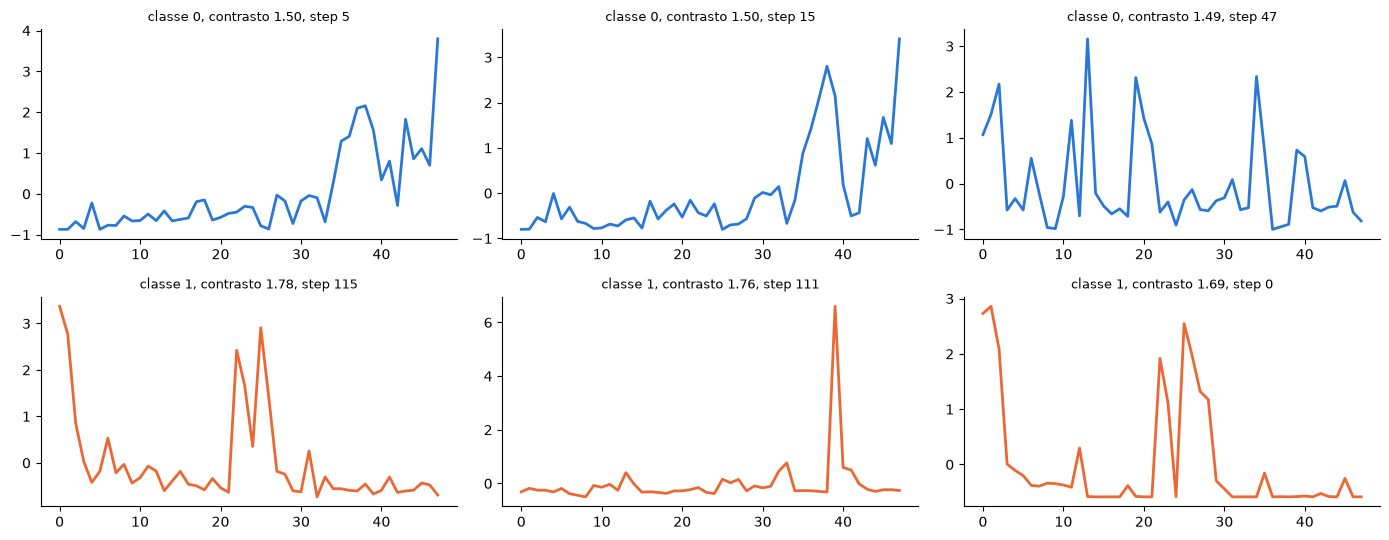

In [61]:
from numpy.lib.stride_tricks import sliding_window_view

def znorm_rows(a, eps=1e-8):
    s = a.std(axis=-1, keepdims=True)
    return (a - a.mean(axis=-1, keepdims=True)) / np.where(s < eps, 1.0, s)

def min_dist(S, X, chunk=500):
    """Distanza z-normalizzata fra la sottosequenza S e la sua migliore posizione in ogni serie di X."""
    S = znorm_rows(np.asarray(S, float)); L = len(S); out = []
    for a in range(0, len(X), chunk):
        W = znorm_rows(sliding_window_view(X[a:a + chunk], L, axis=1))
        out.append(np.sqrt(((W - S) ** 2).sum(axis=2)).min(axis=1))
    return np.concatenate(out) / np.sqrt(L)

def id_auc(score, y_w, id_w):
    g = pd.DataFrame({'s': score, 'y': y_w, 'id': id_w}).groupby('id').agg(s=('s', 'mean'), y=('y', 'first'))
    return roc_auc_score(g.y, g.s)

rows = []
for c in [0, 1]:
    T_c = pool_T[c][0]
    for i in candidates[c]:
        Q = T_c[i:i + m]
        score_te = -min_dist(Q, enmo_clean[te]) if c == 1 else min_dist(Q, enmo_clean[te])   # score alto = più classe 1
        score_tr = -min_dist(Q, enmo_clean[tr]) if c == 1 else min_dist(Q, enmo_clean[tr])
        rows.append({'classe sorgente': c, 't': i, 'step locale': i % 201, 'contrasto': round(contrast[c][i], 2),
                     'P_AA': round(P_self[c][i], 2), 'P_AB': round(P_cross[c][i], 2),
                     'AUC id (train)': round(id_auc(score_tr, y[tr], ids[tr]), 3),
                     'AUC id (test)': round(id_auc(score_te, y[te], ids[te]), 3)})
contrast_table = pd.DataFrame(rows)
print(contrast_table.to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(14, 5.5))
for row, c in enumerate([0, 1]):
    for col, i in enumerate(candidates[c][:3]):
        axes[row, col].plot(zn(pool_T[c][0][i:i + m]), color=C1 if c else C0, linewidth=2)
        axes[row, col].set_title(f'classe {c}, contrasto {contrast[c][i]:.2f}, step {i % 201}', fontsize=9)
        axes[row, col].spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.show()

**Risultato e relazione con gli shapelet:**

- **Contrasto.** La distribuzione è centrata vicino a zero (media -0.05 e +0.03, deviazione standard ~0.41). In forma z-normalizzata, quindi, una sottosequenza di una classe trova di solito un gemello anche nell'altra. I discord globali (d≈7) non sono concentrati in una classe.
- **Forme candidate.** Quelle della classe 0 tendono a mostrare una salita verso l'attività, quelle della classe 1 tratti quieti con picchi isolati. Il loro potere predittivo però non regge: l'AUC per id sul test va da 0.35 a 0.68 e diverse sono **sotto 0.5**, cioè nella direzione opposta a quella attesa. Selezionando il massimo contrasto fra circa 20000 sottosequenze per classe si trovano anche forme rare per caso, soprattutto con 98 finestre per classe.
- **Motif, discord e shapelet.** Sono tre domande diverse sulle stesse sottosequenze:
  - un **motif** si ripete, senza riferimento alle classi, quindi è un candidato shapelet solo se si ripete in una classe e non nell'altra;
  - un **discord** è raro ovunque, quindi è di solito un cattivo shapelet: separa quella singola serie, non una classe;
  - uno **shapelet** è definito dalla separazione, quindi non deve essere né il più frequente né il più raro. Il contrasto `P_AB - P_AA` è il ponte formale fra le tre nozioni.

  In questi dati i motif più forti (picchi isolati) compaiono in entrambe le classi, quindi non sono buoni shapelet: lo verifichiamo sugli shapelet veri nella sezione di classificazione.